In [1]:
import pandas as pd                 # 표(데이터프레임)를 다루는 라이브러리
import matplotlib.pyplot as plt     # 그래프를 그리는 라이브러리

In [ ]:
#회사의 월별 매출액 data
df = pd.read_csv('data/revenue.csv')  # CSV 파일을 표(데이터프레임)로 읽기
df                                    # 셀 마지막 줄에 변수만 쓰면 내용이 출력됨

,month,revenue
0,1,35.8
1,2,29.7
2,3,36.3
3,4,39.6
4,5,45.5
5,6,49.4
6,7,105.1
7,8,123.5
8,9,155.4
9,10,221.8


In [3]:
# sum() : 열마다 모든 값을 더한 합계 (결과는 열마다 숫자 하나)
# month 합계(78)는 의미 없는 값이고, revenue 합계(1365)가 1년 총매출
df.sum()

month        78.0
revenue    1365.0
dtype: float64

In [4]:
# cumsum() : 누적합 (cumulative sum). 첫 행부터 그 행까지 더한 값을 행마다 계산
# 1월 = 35.8 / 2월 = 35.8 + 29.7 = 65.5 / 3월 = 65.5 + 36.3 = 101.8 ...
# 마지막 값(1365.0)은 sum() 으로 구한 총합과 같음
df['revenue'].cumsum()

0       35.8
1       65.5
2      101.8
3      141.4
4      186.9
5      236.3
6      341.4
7      464.9
8      620.3
9      842.1
10    1099.7
11    1365.0
Name: revenue, dtype: float64

In [ ]:
# 계산한 누적합을 revenue_cumsum 이라는 새 열로 추가 (df['새 열 이름'] = 값)
df['revenue_cumsum'] = df['revenue'].cumsum() # 누적합
df

,month,revenue,revenue_cumsum
0,1,35.8,35.8
1,2,29.7,65.5
2,3,36.3,101.8
3,4,39.6,141.4
4,5,45.5,186.9
5,6,49.4,236.3
6,7,105.1,341.4
7,8,123.5,464.9
8,9,155.4,620.3
9,10,221.8,842.1


<Axes: xlabel='month'>

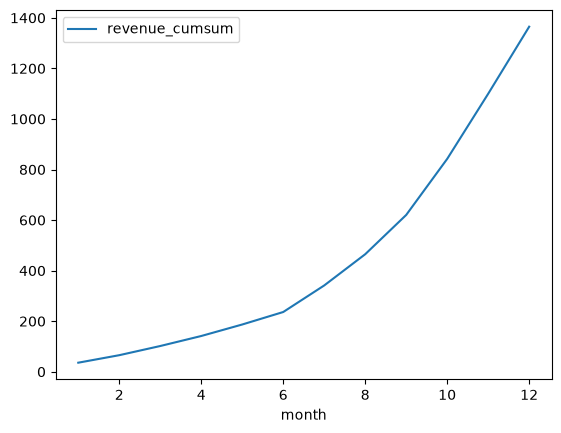

In [6]:
# 누적 매출을 선 그래프로 (kind 를 안 쓰면 기본이 선 그래프)
# x : x축에 쓸 열, y : y축에 쓸 열
df.plot(x='month', y='revenue_cumsum')

<Axes: xlabel='month'>

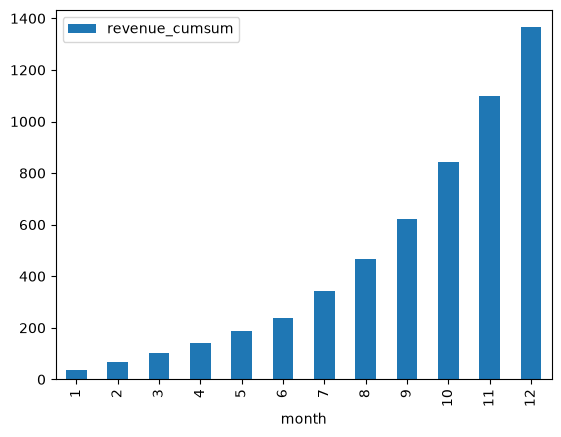

In [7]:
# kind='bar' : 같은 데이터를 막대 그래프로
df.plot(x='month', y='revenue_cumsum', kind='bar')

In [8]:
# 연도별 이자율 data (0.0546 = 5.46%)
interest_df = pd.read_csv('data/interest.csv')
interest_df

,year,interest
0,2001,0.0546
1,2002,0.0471
2,2003,0.0415
3,2004,0.0375
4,2005,0.0357
5,2006,0.0436
6,2007,0.0501
7,2008,0.0567
8,2009,0.0323
9,2010,0.0318


In [9]:
# 이자율에 1을 더해 '몇 배가 되는지'로 바꾸기
# 예) 이자율 0.0546 → 1.0546 : 1년 뒤 원금이 1.0546배가 됨
# 열에 숫자를 더하면 모든 행에 한 번에 더해짐
interest_df['multiple'] = interest_df['interest'] +1
interest_df

,year,interest,multiple
0,2001,0.0546,1.0546
1,2002,0.0471,1.0471
2,2003,0.0415,1.0415
3,2004,0.0375,1.0375
4,2005,0.0357,1.0357
5,2006,0.0436,1.0436
6,2007,0.0501,1.0501
7,2008,0.0567,1.0567
8,2009,0.0323,1.0323
9,2010,0.0318,1.0318


In [11]:
# multiple 의 누적합
# 배수는 해마다 '곱해져서' 불어나므로 더한 값(누적합)은 의미가 없음
# → 몇 배가 됐는지 보려면 누적곱 cumprod() 를 써야 함
interest_df['multiple'].cumprod()

0     1.054600
1     1.104272
2     1.150099
3     1.193228
4     1.235826
5     1.289708
6     1.354322
7     1.431112
8     1.477337
9     1.524317
10    1.580564
11    1.634777
12    1.678916
13    1.719546
14    1.749122
15    1.774834
16    1.801634
17    1.834784
18    1.866710
19    1.886123
Name: multiple, dtype: float64

In [12]:
interest_df['cumulative_multiple'] = interest_df['multiple'].cumprod()
interest_df

,year,interest,multiple,cumulative_multiple
0,2001,0.0546,1.0546,1.054600
1,2002,0.0471,1.0471,1.104272
2,2003,0.0415,1.0415,1.150099
3,2004,0.0375,1.0375,1.193228
4,2005,0.0357,1.0357,1.235826
5,2006,0.0436,1.0436,1.289708
6,2007,0.0501,1.0501,1.354322
7,2008,0.0567,1.0567,1.431112
8,2009,0.0323,1.0323,1.477337
9,2010,0.0318,1.0318,1.524317
